# Exploring Spain Mobility Data

## 1. Setup

In [3]:
from pyspainmobility import Mobility, Zones # MITMA OD data + municipality polygons (for map not extraction)
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd # pandas with geometry
from pathlib import Path
import numpy as np

data_path = "/Users/theocoronges/Documents/internship2026/data"
data_dir = Path(data_path)

## 2. Download 

In [ ]:
# clear data folder

for f in data_dir.iterdir():
    f.unlink()

### 2.1. First Model

In [2]:
# dowloading data

mob = Mobility(
    version=2, # post 2022 (covid)
    zones="municipalities", # spacial unit, districts (finer) or lua (coarser)
    start_date="2024-10-14",
    end_date="2024-10-20",
    output_directory=data_path,
    #social_agg=True
)


RuntimeError: Could not reach the MITMA open-data server while fetching the list of available dates for version 2. This is usually a temporary problem on the government's side (e.g. HTTP 500 / service maintenance). Please wait a few minutes and try again. Original error: HTTP Error 500: Internal Server Error

## 3. Load data

In [5]:
# read data
od = pd.read_parquet(data_dir / "Viajes_municipios_2024-10-14_2024-10-20_v2.parquet")

# load zone geometries from the cached geojson.
# the Zones class re-fetches MITMA's RSS feed on every call, which returns
# HTTP 500 when their server is down; reading the cached file needs no network.
gdf = gpd.read_file(data_dir / "municipios_2.geojson")

### fix int formatting (claude), AM figure out (documentation), expand to a month, once formatting fixed od simplified matrix

## 4. Explore the data

In [21]:
# exploring

od.shape

(38732108, 8)

In [11]:
od.head(10)

,date,hour,id_origin,id_destination,activity_origin,activity_destination,n_trips,trips_total_length_km
0,2024-10-14,0,01001,01001,home,other_frequent,4.069,16.911
1,2024-10-14,0,01001,01009_AM,other_frequent,home,4.91,24.317
2,2024-10-14,0,01001,01009_AM,work_or_study,home,2.222,14.696
3,2024-10-14,0,01001,01009_AM,work_or_study,other_frequent,2.939,11.151
4,2024-10-14,0,01001,01059,home,other_frequent,2.403,27.652
5,2024-10-14,0,01001,01059,home,other_non_frequent,4.763,54.596
6,2024-10-14,0,01001,01059,home,work_or_study,2.063,25.998
7,2024-10-14,0,01001,01059,other_frequent,home,20.018,265.203
8,2024-10-14,0,01001,01059,other_non_frequent,home,2.857,31.701
9,2024-10-14,0,01001,01059,other_non_frequent,other_non_frequent,3.372,41.473


In [19]:
od.columns.tolist()

['date',
 'hour',
 'id_origin',
 'id_destination',
 'activity_origin',
 'activity_destination',
 'n_trips',
 'trips_total_length_km']

In [18]:
od.dtypes

date                              string
hour                      int64[pyarrow]
id_origin                         string
id_destination                    string
activity_origin                   string
activity_destination              string
n_trips                  double[pyarrow]
trips_total_length_km    double[pyarrow]
dtype: object

In [13]:
print(od["date"].unique())

<ArrowStringArray>
['2024-10-14', '2024-10-15', '2024-10-16', '2024-10-17', '2024-10-18',
 '2024-10-19', '2024-10-20']
Length: 7, dtype: string


In [ ]:
# zone geometries

gdf.head()

## 5. Phase 1 — flows

In [14]:
# phase 1

trip_col = "n_trips"
origin_col = "id_origin"
dest_col = "id_destination"
date_col = "date"
hour_col = "hour"

In [ ]:
# 1.1 total trips for the week

od[trip_col].sum()

987026217.2989994

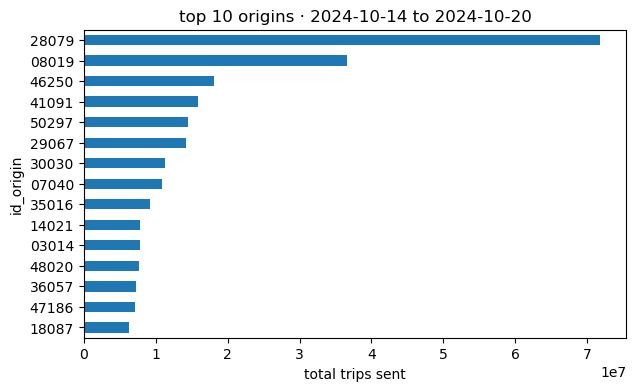

In [25]:
# 1.2 top 15 origins

top_origins = od.groupby(origin_col)[trip_col].sum().sort_values(ascending=False).head(15)

top_origins.iloc[::-1].plot(kind="barh", figsize=(7, 4))
plt.title("top 10 origins · 2024-10-14 to 2024-10-20")
plt.xlabel("total trips sent")
plt.show()

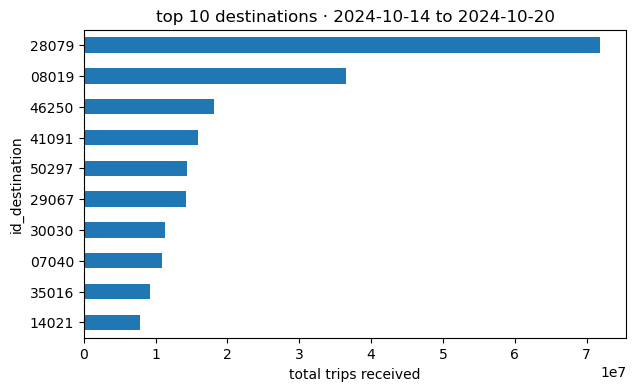

In [24]:
# 1.3 top 15 destinations

top_dests = od.groupby(dest_col)[trip_col].sum().sort_values(ascending=False).head(10)

top_dests.iloc[::-1].plot(kind="barh", figsize=(7, 4))
plt.title("top 10 destinations · 2024-10-14 to 2024-10-20")
plt.xlabel("total trips received")
plt.show()

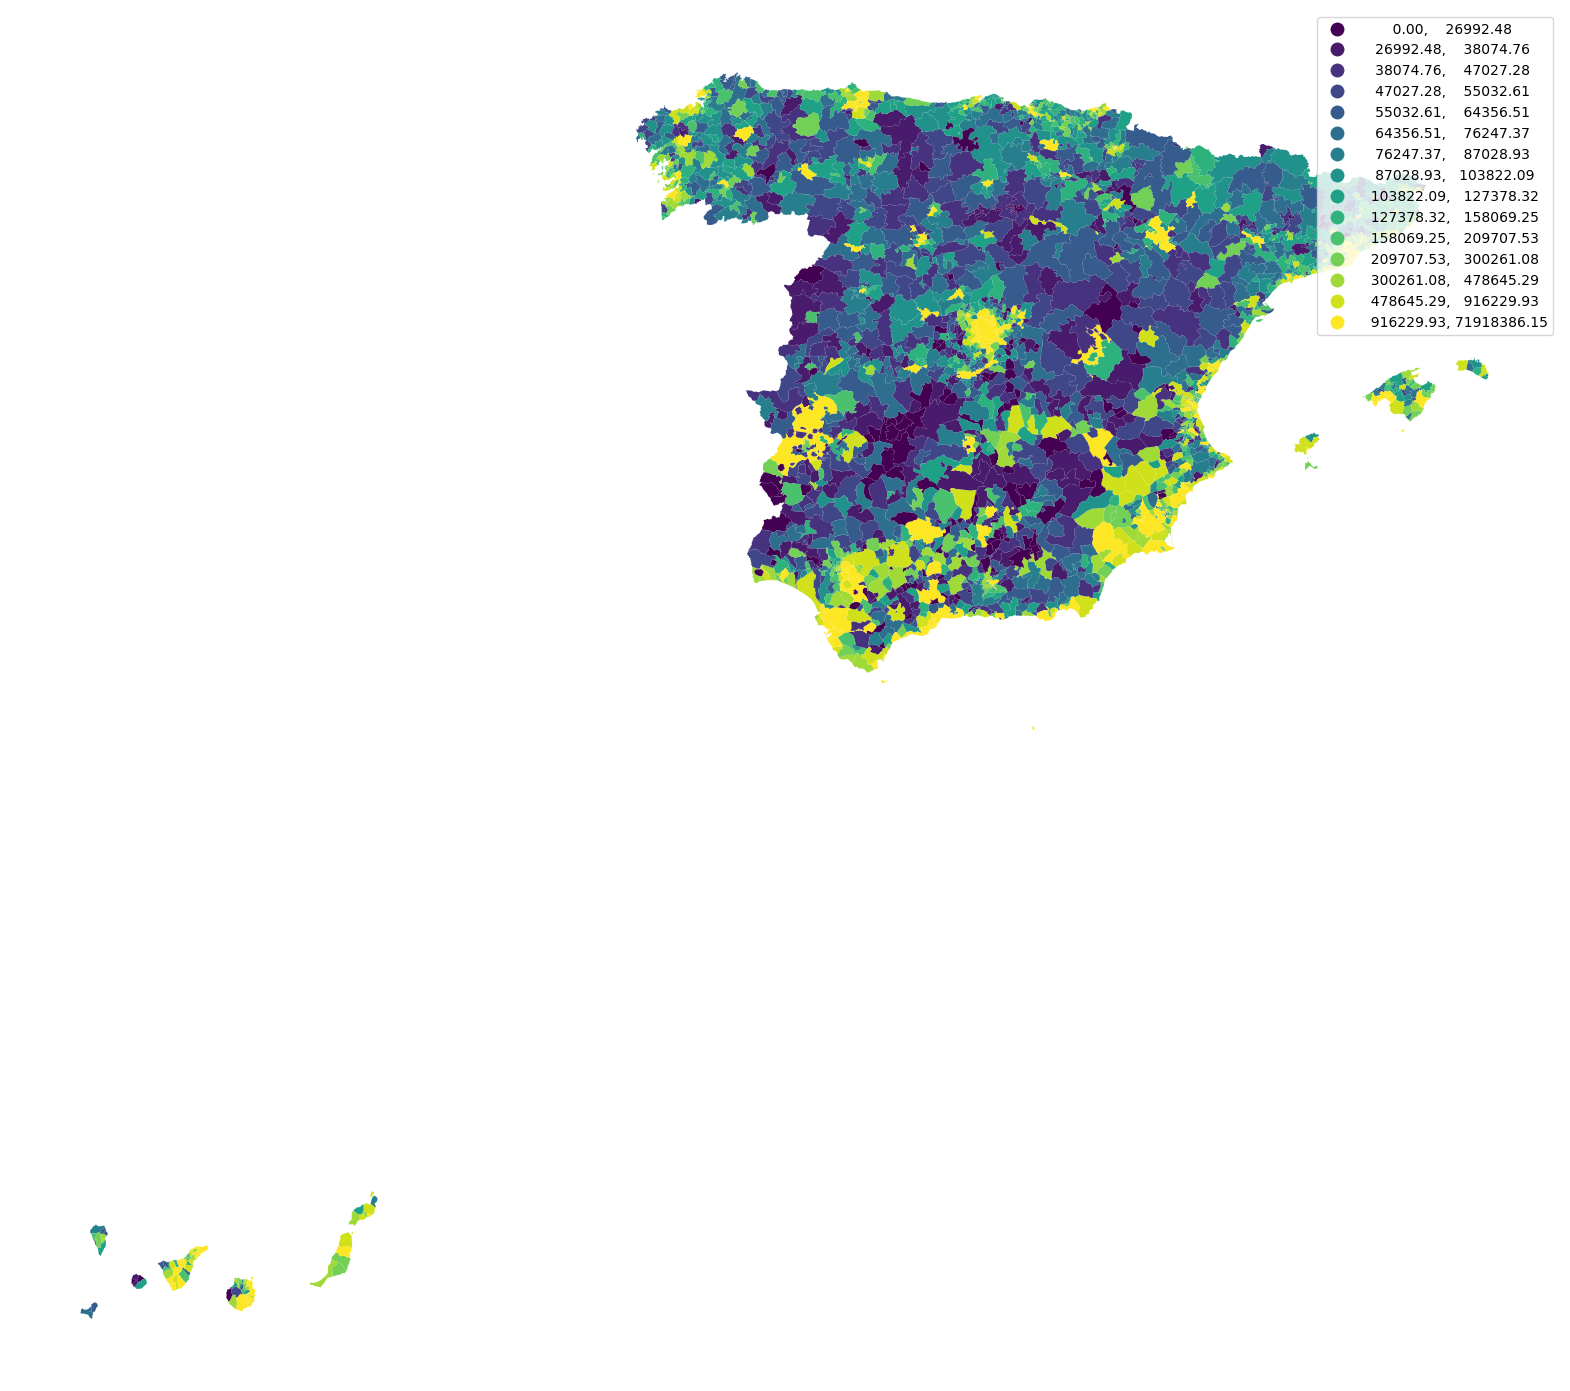

In [46]:
# mapping

inbound = od.groupby(dest_col)[trip_col].sum().rename("inbound") # store trips per destination
joined = gdf.merge(inbound, left_on="id", right_index=True, how="left").fillna({"inbound": 0}) # merge total trips per destination onto geometric dest

map = joined.plot(column="inbound", cmap="viridis", legend=True, scheme="quantiles", k=15, figsize=(20, 20)) # k=7 for bins for better visualization
map.set_axis_off()

### Madrid

In [ ]:
# filtering to madrid (trips with origin or destination in province 28)

mad = "28"
od_madrid = od[
    od[origin_col].astype(str).str.startswith(mad)
    | od[dest_col].astype(str).str.startswith(mad)
]

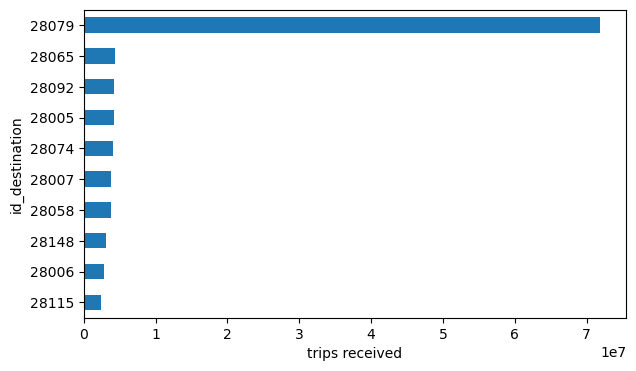

In [ ]:
# top origins and destinations + bar charts

top_origins_mad = od_madrid.groupby(origin_col)[trip_col].sum().sort_values(ascending=False).head(10)

top_dests_mad  = od_madrid.groupby(dest_col)[trip_col].sum().sort_values(ascending=False).head(10)

top_dests_mad.iloc[::-1].plot(kind="barh", figsize=(7, 4))
plt.xlabel("trips received")
plt.show()

In [ ]:
# exploring distribution of mobility

print(f"{round(float((top_dests_mad.head(10).sum() * 100 / od_madrid[trip_col].sum())))}% come from top 10")

72 % come from top 10


In [ ]:
# mapping madrid

# filter geometries to madrid province
gdf_madrid = gdf[gdf["id"].astype(str).str.startswith("28")]

# inbound trips per madrid destination
inbound_mad = od_madrid.groupby(dest_col)[trip_col].sum().rename("inbound")

# merge inbound trips onto madrid geometries via the id column
joined_mad = gdf_madrid.merge(inbound_mad, left_on="id", right_index=True, how="left").fillna({"inbound": 0})

# plot
ax = joined_mad.plot(column="inbound", cmap="viridis", legend=True,
                    scheme="quantiles", k=7, figsize=(10, 10))
ax.set_axis_off()
ax.set_title("Madrid province inbound trips · 2024-10-14 to 2024-10-20")

### Temporal

Text(0, 0.5, 'trips')

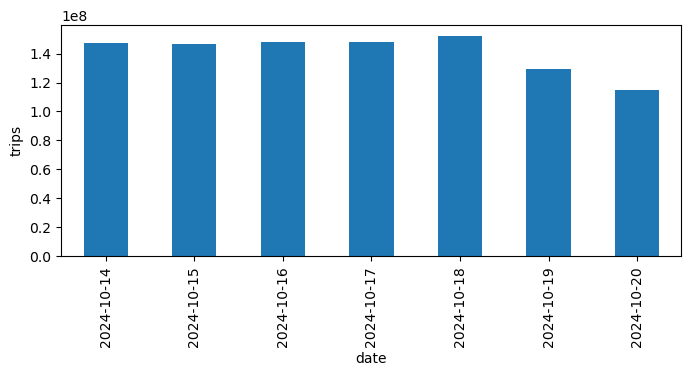

In [43]:
# daily chart

daily = od.groupby(date_col)[trip_col].sum()
daily.plot(kind="bar", figsize=(8, 3))
plt.ylabel("trips")

## 6. Gravity model

Now for the linear regression first aggregate each OD pair into a single column.

Considerations from previous discussion:

AM thing: agregación de municipios, due to privacy laws, not AM - PM

. seperator: has to be decimal, if not total trips would be way off ~1b for the week



In [6]:
# first formatting + merging population of both origin and destination onto new OD dataframe.

od_gm = od[['id_origin', 'id_destination', 'n_trips', 'trips_total_length_km']]

lookup_tool = gdf.set_index("id")["population"]

od_gm["Pi"] = od_gm["id_origin"].map(lookup_tool)
od_gm["Pj"] = od_gm["id_destination"].map(lookup_tool)

# renaming to cleaner names

od_gm = od_gm.rename(columns={"id_origin": "origin", "id_destination": "destination", "n_trips": "trips", "trips_total_length_km": "total_km"})

# dropping same zone rows

#od_gm = od_gm[od_gm["origin"] != od_gm["destination"]]

# aggregation

od_gm = od_gm.groupby(["origin", "destination"], as_index=False).agg({"trips": "sum", "total_km": "sum", "Pi": "first", "Pj": "first"})

In [7]:
# making avg distance columns and dropping total distance

od_gm["avg_distance"] = od_gm["total_km"] / od_gm["trips"]

od_gm = od_gm.drop('total_km', axis=1)

In [8]:
# casting to float64 for everything

for col in ["trips", "avg_distance", "Pi", "Pj"]:
    od_gm[col] = od_gm[col].astype("float64")

In [10]:
od_gm.head(5)

,origin,destination,trips,Pi,Pj,avg_distance
0,01001,01001,653.743,2925.0,2925.0,3.993415
1,01001,01002,47.096,2925.0,10307.0,46.019896
2,01001,01004_AM,6.615,2925.0,3005.0,59.296145
3,01001,01009_AM,3899.852,2925.0,4599.0,6.267452
4,01001,01010,6.478,2925.0,2951.0,49.461871


In [11]:
# log

import numpy as np

od_gm["log_trips"] = np.log(od_gm["trips"])
od_gm["log_Pi"] = np.log(od_gm["Pi"])
od_gm["log_Pj"] = np.log(od_gm["Pj"])
od_gm["log_dij"] = np.log(od_gm["avg_distance"])

In [12]:
# checks

od_gm[["log_trips", "log_Pi", "log_Pj", "log_dij"]].describe()
od_gm[["log_trips", "log_Pi", "log_Pj", "log_dij"]].isna().sum()

log_trips        0
log_Pi       39096
log_Pj       37005
log_dij          0
dtype: int64

In [14]:
# investigation, why so many missing?

missing_o = od_gm[od_gm["Pi"].isna()]["origin"].unique()
missing_d = od_gm[od_gm["Pj"].isna()]["destination"].unique()
print(f"unique missing origins: {len(missing_o)}")
print(f"unique missing destinations: {len(missing_d)}")
missing_o[:50]

unique missing origins: 118
unique missing destinations: 118


<ArrowStringArray>
['FR101', 'FR102', 'FR103', 'FR104', 'FR105', 'FR106', 'FR107', 'FR108',
 'FRB01', 'FRB02', 'FRB03', 'FRB04', 'FRB05', 'FRB06', 'FRC11', 'FRC12',
 'FRC13', 'FRC14', 'FRC21', 'FRC22', 'FRC23', 'FRC24', 'FRD11', 'FRD12',
 'FRD13', 'FRD21', 'FRD22', 'FRE11', 'FRE12', 'FRE21', 'FRE22', 'FRE23',
 'FRF11', 'FRF12', 'FRF21', 'FRF22', 'FRF23', 'FRF24', 'FRF31', 'FRF32',
 'FRF33', 'FRF34', 'FRG01', 'FRG02', 'FRG03', 'FRG04', 'FRG05', 'FRH01',
 'FRH02', 'FRH03']
Length: 50, dtype: string

In [15]:
# dropping these for now, no population data available for france.

od_gm = od_gm.dropna(subset=["Pi", "Pj"])

od_gm[["log_trips", "log_Pi", "log_Pj", "log_dij"]].isna().sum()

log_trips    0
log_Pi       0
log_Pj       0
log_dij      0
dtype: int64

In [16]:
# regression

import statsmodels.formula.api as smf

model = smf.ols("log_trips ~ log_Pi + log_Pj + log_dij", data=od_gm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_trips   R-squared:                       0.653
Model:                            OLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                 5.475e+05
Date:                Wed, 24 Jun 2026   Prob (F-statistic):               0.00
Time:                        10:52:06   Log-Likelihood:            -1.3417e+06
No. Observations:              873056   AIC:                         2.683e+06
Df Residuals:                  873052   BIC:                         2.683e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5087      0.013     39.651      0.0

In [ ]:
# negating because the coefficient is negative
gamma = -model.params["log_dij"]    
r2 = model.rsquared
print(f"gamma = {gamma:.3f}")
print(f"R2 = {r2:.3f}")

gamma = 1.494
R² = 0.642
